In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn

In [29]:
from tensorflow.keras.datasets import imdb
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=10000
)
print("Dataset loaded successfully!")
print("Training reviews:", len(x_train))
print("Testing reviews:", len(x_test))

Dataset loaded successfully!
Training reviews: 25000
Testing reviews: 25000


In [30]:

print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)
print("\nFirst review (numerical format):")
print(x_train[0])
print("\nFirst review sentiment:")
print(y_train[0])

Training data shape: (25000,)
Training labels shape: (25000,)
Testing data shape: (25000,)
Testing labels shape: (25000,)

First review (numerical format):
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4

In [31]:

word_index = imdb.get_word_index()
reverse_word_index = {
    value: key for key, value in word_index.items()
}
decoded_review = " ".join(
    reverse_word_index.get(i - 3, "?")
    for i in x_train[0]
    if i >= 3
)
print("First movie review:")
print(decoded_review)
print("\nSentiment:", "Positive" if y_train[0] == 1 else "Negative")

First movie review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't y

In [32]:

unique, counts = np.unique(y_train, return_counts=True)
print("Training sentiment distribution:")
for label, count in zip(unique, counts):
    sentiment = "Negative" if label == 0 else "Positive"
    print(sentiment, ":", count)

Training sentiment distribution:
Negative : 12500
Positive : 12500


In [33]:

for i in range(5):
    decoded_review = " ".join(
        reverse_word_index.get(word - 3, "?")
        for word in x_train[i]
        if word >= 3
    )
    sentiment = "Positive" if y_train[i] == 1 else "Negative"
    print(f"\nReview {i + 1}:")
    print(decoded_review[:500])
    print("Sentiment:", sentiment)
    print("-" * 60)


Review 1:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to 
Sentiment: Positive
------------------------------------------------------------

Review 2:
big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is completely laughable the best is the end showdown with the cop and how he worked out who the killer is it'

In [34]:

def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(word - 3, "?")
        for word in encoded_review
        if word >= 3
    )
train_reviews = [decode_review(review) for review in x_train]
test_reviews = [decode_review(review) for review in x_test]
print("Training reviews converted:", len(train_reviews))
print("Testing reviews converted:", len(test_reviews))
print("\nSample review:")
print(train_reviews[0][:500])

Training reviews converted: 25000
Testing reviews converted: 25000

Sample review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to 


In [35]:

train_df = pd.DataFrame({
    "review": train_reviews,
    "sentiment": y_train
})
test_df = pd.DataFrame({
    "review": test_reviews,
    "sentiment": y_test
})
train_df.head()

,review,sentiment
0,this film was just brilliant casting location ...,1
1,big hair big boobs bad music and a giant safet...,0
2,this has to be one of the worst films of the 1...,0
3,the at storytelling the traditional sort many ...,1
4,worst mistake of my life br br i picked this m...,0


In [36]:

print("Missing values in training data:")
print(train_df.isnull().sum())
print("\nDuplicate reviews in training data:")
print(train_df.duplicated().sum())
print("\nTraining dataset information:")
train_df.info()

Missing values in training data:
review       0
sentiment    0
dtype: int64

Duplicate reviews in training data:
99

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     25000 non-null  object
 1   sentiment  25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB


In [37]:

train_df = train_df.drop_duplicates(subset=["review"])
train_df = train_df.reset_index(drop=True)
print("Dataset size after removing duplicates:", len(train_df))
print("Remaining duplicates:", train_df.duplicated(subset=["review"]).sum())

Dataset size after removing duplicates: 24901
Remaining duplicates: 0


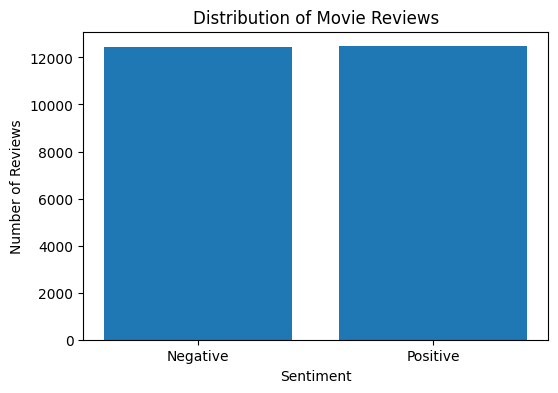

In [38]:

sentiment_counts = train_df["sentiment"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(
    ["Negative", "Positive"],
    sentiment_counts.values
)
plt.title("Distribution of Movie Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [39]:

X_train = train_df["review"]
y_train_clean = train_df["sentiment"]
X_test = test_df["review"]
y_test_clean = test_df["sentiment"]
print("X_train:", X_train.shape)
print("y_train:", y_train_clean.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test_clean.shape)

X_train: (24901,)
y_train: (24901,)
X_test: (25000,)
y_test: (25000,)


In [40]:
import re
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text
X_train_clean = X_train.apply(clean_text)
X_test_clean = X_test.apply(clean_text)
print("Original review:")
print(X_train.iloc[0][:300])
print("\nCleaned review:")
print(X_train_clean.iloc[0][:300])

Original review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a re

Cleaned review:
this film was just brilliant casting location scenery story direction everyones really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a rea


In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)
X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf = tfidf.transform(X_test_clean)
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (24901, 20000)
Testing data shape: (25000, 20000)


In [42]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train_clean)
print("Model training completed successfully!")

Model training completed successfully!


In [43]:

y_pred = model.predict(X_test_tfidf)
print("Predictions completed successfully!")
for i in range(10):
    actual = "Positive" if y_test_clean.iloc[i] == 1 else "Negative"
    predicted = "Positive" if y_pred[i] == 1 else "Negative"
    print(f"Review {i+1}: Actual = {actual}, Predicted = {predicted}")

Predictions completed successfully!
Review 1: Actual = Negative, Predicted = Negative
Review 2: Actual = Positive, Predicted = Positive
Review 3: Actual = Positive, Predicted = Positive
Review 4: Actual = Negative, Predicted = Negative
Review 5: Actual = Positive, Predicted = Positive
Review 6: Actual = Positive, Predicted = Positive
Review 7: Actual = Positive, Predicted = Positive
Review 8: Actual = Negative, Predicted = Negative
Review 9: Actual = Negative, Predicted = Positive
Review 10: Actual = Positive, Predicted = Positive


In [44]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test_clean, y_pred)
print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 89.548 %


In [45]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test_clean,
    y_pred,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.90      0.89      0.89     12500
    Positive       0.89      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



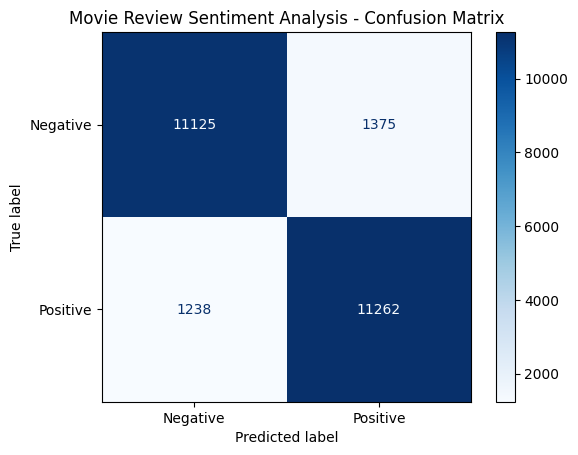

In [46]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test_clean, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
display.plot(cmap="Blues")
plt.title("Movie Review Sentiment Analysis - Confusion Matrix")
plt.show()

In [47]:

custom_reviews = [
    "This movie was amazing and the acting was brilliant",
    "The movie was boring and the story was terrible",
    "I really enjoyed this film and loved every scene",
    "Worst movie ever, completely disappointing"
]
cleaned_reviews = [clean_text(review) for review in custom_reviews]
custom_tfidf = tfidf.transform(cleaned_reviews)
custom_predictions = model.predict(custom_tfidf)
for review, prediction in zip(custom_reviews, custom_predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("-" * 60)

Review: This movie was amazing and the acting was brilliant
Predicted sentiment: Positive
------------------------------------------------------------
Review: The movie was boring and the story was terrible
Predicted sentiment: Negative
------------------------------------------------------------
Review: I really enjoyed this film and loved every scene
Predicted sentiment: Positive
------------------------------------------------------------
Review: Worst movie ever, completely disappointing
Predicted sentiment: Negative
------------------------------------------------------------


In [48]:
import gradio as gr
def predict_sentiment(review):
    cleaned = clean_text(review)
    review_tfidf = tfidf.transform([cleaned])
    prediction = model.predict(review_tfidf)[0]
    if prediction == 1:
        return "Positive 😊"
    else:
        return "Negative 😞"
demo = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(
        lines=5,
        placeholder="Enter your movie review here..."
    ),
    outputs=gr.Textbox(label="Predicted Sentiment"),
    title="Movie Review Sentiment Analysis",
    description="Enter a movie review to predict whether it is positive or negative."
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2b0e0645d1a06c5443.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [49]:
import joblib
joblib.dump(model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [50]:
from google.colab import files
files.download("sentiment_model.pkl")
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>